# Conditional kNN baseline - Arquitectura B

Este notebook implementa un baseline generativo context-only para CVAE-B. Cada muestra es una provincia-dia: `X` contiene el perfil horario de 24 horas y `C` contiene calendario, clima e indicadores socioeconomicos de esa provincia-dia.

El modelo no aprende un espacio latente. Para cada contexto nuevo `c0`, busca contextos similares en `C_train`, samplea uno de sus vecinos con pesos decrecientes en la distancia y usa el perfil historico `X_train` de ese vecino como escenario generado. Opcionalmente agrega ruido gaussiano chico en escala normalizada, lo que lo convierte en una version local tipo KDE.

La pregunta del experimento es directa: cuanto de `p(x | c)` se puede explicar usando solo el contexto observado, sin la complejidad adicional del CVAE-B.

## Setup

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from conditional_knn_baseline_b import run_conditional_knn_baseline_b

processed_dir = provinces_root / "data" / "processed"
splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "conditional_knn_b"
output_dir

PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_knn_b')

## Datos y leakage

Se reutiliza `run_preprocessing_b`, el mismo preprocessing que CVAE-B. El split temporal queda fijo: train usa 2019, 2021, 2022 y 2023; validation usa 2024; test usa 2025 y enero-abril de 2026. Los scalers se ajustan solo con train.

El kNN se ajusta unicamente sobre `C_train`. En generation, el modelo recibe solo `C`; no usa etiquetas de provincia como input explicito. `provinces_val` y `provinces_test` se usan solo para reportar metricas por provincia.

## Ejecutar o cargar resultados

La grilla de hiperparametros es la pedida para el baseline: `k = [10, 25, 50, 100]`, `tau_scale = [0.25, 0.5, 1.0, 2.0]` y `bandwidth_x = [0.0, 0.02, 0.05, 0.10]`. Para que la grilla completa sea razonable en tiempo, validation usa 200 escenarios por configuracion. La evaluacion final en test usa 500 escenarios, igual que CVAE-B. Test no participa en la seleccion.

In [2]:
RUN_ANALYSIS = False

config = SimpleNamespace(
    processed_dir=processed_dir,
    splits_dir=splits_dir,
    output_dir=output_dir,
    seed=42,
    k_grid=[10, 25, 50, 100],
    tau_scale_grid=[0.25, 0.5, 1.0, 2.0],
    bandwidth_x_grid=[0.0, 0.02, 0.05, 0.10],
    n_scenarios_validation=200,
    n_scenarios_test=500,
    plot_days=4,
)

if RUN_ANALYSIS:
    display(run_conditional_knn_baseline_b(config))
else:
    print(f"Usando resultados guardados en {output_dir}")

Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/conditional_knn_b


In [3]:
required_files = [
    output_dir / "config.json",
    output_dir / "validation_grid.csv",
    output_dir / "selection_comparison.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_province.csv",
    output_dir / "metrics_by_month.csv",
    output_dir / "coverage_by_province_hour.csv",
    output_dir / "rmse_by_province_hour.csv",
    output_dir / "cvae_b_comparison.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Faltan resultados. Cambiar RUN_ANALYSIS a True. Archivos: {missing_files}")

## Configuracion guardada

In [4]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

display(pd.Series(saved_config, name="value").to_frame())

,value
bandwidth_x_grid,"[0.0, 0.02, 0.05, 0.1]"
k_grid,"[10, 25, 50, 100]"
model,conditional_knn_baseline_b
n_scenarios_test,500
n_scenarios_validation,200
processed_dir,/Users/victoriapersico/Desktop/Ingenieria/Terc...
seed,42
selected_bandwidth_x,0.0
selected_k,25
selected_tau_scale,1.0


## Seleccion en validation

La seleccion principal usa el mismo criterio generativo que los otros experimentos: primero coverage P5-P95 mas cercano a 90%, luego menor sharpness, menor RMSE del perfil medio y menor MMD. Todas estas metricas se calculan en validation; test se evalua una sola vez despues de fijar la configuracion final.

,k,tau_scale,bandwidth_x,n_scenarios_validation,coverage_gap,val_mae_global,val_rmse_global,val_mean_profile_rmse,val_mape_energy,val_coverage,val_sharpness,val_diversity_ratio,val_mmd
24,25,1.00,0.00,200,0.403005,55.442997,139.007065,144.982849,8.619025,90.403005,312.549967,0.062043,0.004032
28,25,2.00,0.00,200,0.455787,56.614014,142.697220,148.981903,8.835406,90.455787,317.961045,0.063078,0.004072
21,25,0.50,0.02,200,0.770409,52.850758,135.104187,138.537170,7.911890,90.770409,295.390569,0.058952,0.004000
6,10,0.50,0.05,200,0.786451,51.895664,133.670120,132.005127,7.685234,90.786451,265.305658,0.051559,0.004000
20,25,0.50,0.00,200,0.849789,52.979595,135.149750,136.182037,7.948866,89.150211,287.369549,0.057889,0.004016
34,50,0.25,0.05,200,0.900501,54.099964,141.899841,136.639191,7.816805,89.099499,244.876480,0.050235,0.004000
3,10,0.25,0.10,200,1.408449,57.894005,154.761917,151.554443,8.200235,91.408449,284.225567,0.055587,0.004000
10,10,1.00,0.05,200,1.496937,52.783569,135.810318,134.685455,7.911973,91.496937,280.263669,0.053943,0.004000
14,10,2.00,0.05,200,1.543509,53.120403,135.677429,134.429611,8.085466,91.543509,281.944409,0.054342,0.004000
25,25,1.00,0.02,200,1.727211,54.876934,137.221252,143.562439,8.567500,91.727211,318.946214,0.062915,0.004000


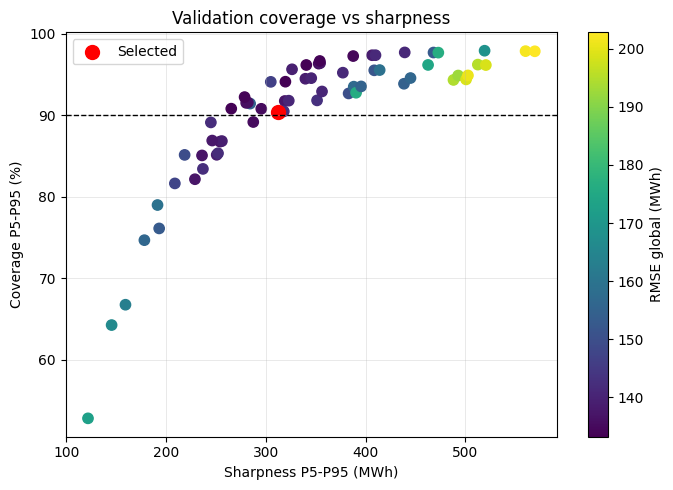

In [5]:
validation_grid = pd.read_csv(output_dir / "validation_grid.csv")
ordered_validation = validation_grid.sort_values(
    ["coverage_gap", "val_sharpness", "val_mean_profile_rmse", "val_mmd"]
)
display(ordered_validation.head(10))

fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(
    validation_grid["val_sharpness"],
    validation_grid["val_coverage"],
    c=validation_grid["val_rmse_global"],
    cmap="viridis",
    s=55,
)
selected = ordered_validation.iloc[0]
ax.scatter(selected["val_sharpness"], selected["val_coverage"], color="red", s=100, label="Selected")
ax.axhline(90.0, color="black", linestyle="--", linewidth=1)
ax.set_title("Validation coverage vs sharpness")
ax.set_xlabel("Sharpness P5-P95 (MWh)")
ax.set_ylabel("Coverage P5-P95 (%)")
ax.grid(linewidth=0.4, alpha=0.5)
ax.legend()
colorbar = fig.colorbar(scatter, ax=ax)
colorbar.set_label("RMSE global (MWh)")
fig.tight_layout()
plt.show()

In [6]:
selection_comparison = pd.read_csv(output_dir / "selection_comparison.csv")
display(selection_comparison.T.rename(columns={0: "value"}))

,value
selection_criterion,validation_generative
k,25
tau_scale,1.0
bandwidth_x,0.0
coverage_gap,0.403005
val_mae_global,55.442997
val_rmse_global,139.007065
val_mean_profile_rmse,144.982849
val_mape_energy,8.619025
val_coverage,90.403005


## Evaluacion final en test

La siguiente tabla corresponde a la configuracion elegida con validation: `k=25`, `tau_scale=1.0`, `bandwidth_x=0.0`. Como `bandwidth_x=0`, el modelo final es un bootstrap ponderado de vecinos historicos, sin ruido adicional en `X`.

In [7]:
overall_metrics = pd.read_csv(output_dir / "metrics_overall.csv")
display(overall_metrics.T.rename(columns={0: "value"}))

row = overall_metrics.iloc[0]
print(f"MAE global: {row['mae_global']:.2f} MWh")
print(f"RMSE global: {row['rmse_global']:.2f} MWh")
print(f"MAPE energia: {row['mape_energy']:.2f}%")
print(f"Coverage P5-P95: {row['coverage']:.2f}%")
print(f"Sharpness P5-P95: {row['sharpness']:.2f} MWh")
print(f"Diversity ratio: {row['diversity_ratio']:.4f}")
print(f"MMD: {row['mmd']:.6f}")

,value
model,conditional_knn_b
k,25
tau_scale,1.0
bandwidth_x,0.0
n_scenarios_test,500
mae_global,59.812572
rmse_global,173.856903
mean_profile_rmse,185.109863
mape_energy,8.967692
coverage,84.232662


MAE global: 59.81 MWh
RMSE global: 173.86 MWh
MAPE energia: 8.97%
Coverage P5-P95: 84.23%
Sharpness P5-P95: 319.62 MWh
Diversity ratio: 0.0634
MMD: 0.004024


## Desglose por provincia, mes y hora

,mae_global,rmse_global,mean_profile_rmse,mape_energy,coverage,sharpness,diversity_ratio,mmd,province,n_samples
0,490.364166,744.001770,795.315979,5.132739,92.371134,2522.103401,0.604088,0.005238,buenos_aires,485
1,115.450508,173.144073,171.878967,6.699608,92.972509,629.008917,0.673283,0.004770,santa_fe,485
2,93.383644,152.551987,137.546967,6.547604,95.756014,574.682671,0.810232,0.004795,cordoba,485
3,87.430588,110.424400,112.372002,14.300722,70.970790,294.660015,1.479847,0.004889,chubut,485
4,56.880535,108.861206,139.989334,8.480451,82.697595,486.663524,1.699706,0.005016,mendoza,485
5,66.533180,92.832619,103.897301,14.230415,71.451890,239.427552,0.567599,0.004549,chaco,485
6,50.646317,77.971558,78.189362,9.320043,88.247423,241.768928,0.760552,0.004710,entre_rios,485
7,41.962082,61.935989,60.497074,8.971067,85.524055,146.621806,0.510720,0.004923,tucuman,485


,mae_global,rmse_global,mean_profile_rmse,mape_energy,coverage,sharpness,diversity_ratio,mmd,month,n_samples
0,70.671692,171.504379,195.039520,9.857697,84.546065,392.026820,0.073695,0.004216,1,1364
1,77.218147,169.596344,205.222702,10.801259,78.185877,408.665159,0.078064,0.004184,2,1232
2,60.755905,154.518265,157.829468,8.800887,84.665200,311.108093,0.064132,0.004144,3,1364
3,40.734344,103.410187,108.437012,7.174650,85.729167,241.969236,0.055246,0.004152,4,1320
4,38.387501,106.813866,112.963501,6.576292,89.516129,256.305644,0.053471,0.004112,5,682
5,74.191574,218.871887,208.599930,9.704778,83.232323,298.384872,0.050696,0.004112,6,660
6,68.206985,193.399643,194.112762,9.097924,78.690127,289.160722,0.049705,0.004160,7,682
7,46.298820,139.512634,138.032272,7.285795,86.259775,268.419983,0.050699,0.004120,8,682
8,46.337067,120.873787,120.935570,7.772180,86.395202,260.737260,0.056235,0.004112,9,660
9,43.483643,104.458397,109.620605,8.605027,87.762708,276.096586,0.063308,0.004112,10,682


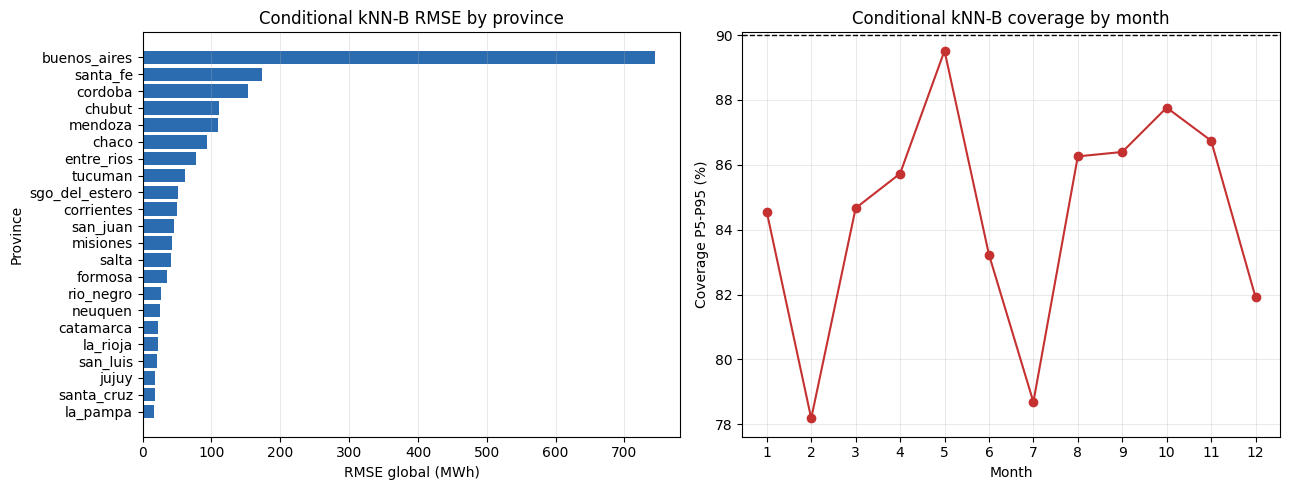

In [8]:
province_metrics = pd.read_csv(output_dir / "metrics_by_province.csv")
month_metrics = pd.read_csv(output_dir / "metrics_by_month.csv")
coverage_by_hour = pd.read_csv(output_dir / "coverage_by_province_hour.csv", index_col=0)
rmse_by_hour = pd.read_csv(output_dir / "rmse_by_province_hour.csv", index_col=0)

display(province_metrics.sort_values("rmse_global", ascending=False).head(8))
display(month_metrics)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
province_ordered = province_metrics.sort_values("rmse_global")
axes[0].barh(province_ordered["province"], province_ordered["rmse_global"], color="#2B6CB0")
axes[0].set_title("Conditional kNN-B RMSE by province")
axes[0].set_xlabel("RMSE global (MWh)")
axes[0].set_ylabel("Province")
axes[0].grid(axis="x", linewidth=0.4, alpha=0.5)

axes[1].plot(month_metrics["month"], month_metrics["coverage"], marker="o", color="#C53030")
axes[1].axhline(90.0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Conditional kNN-B coverage by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Coverage P5-P95 (%)")
axes[1].set_xticks(month_metrics["month"])
axes[1].grid(linewidth=0.4, alpha=0.5)
fig.tight_layout()
plt.show()

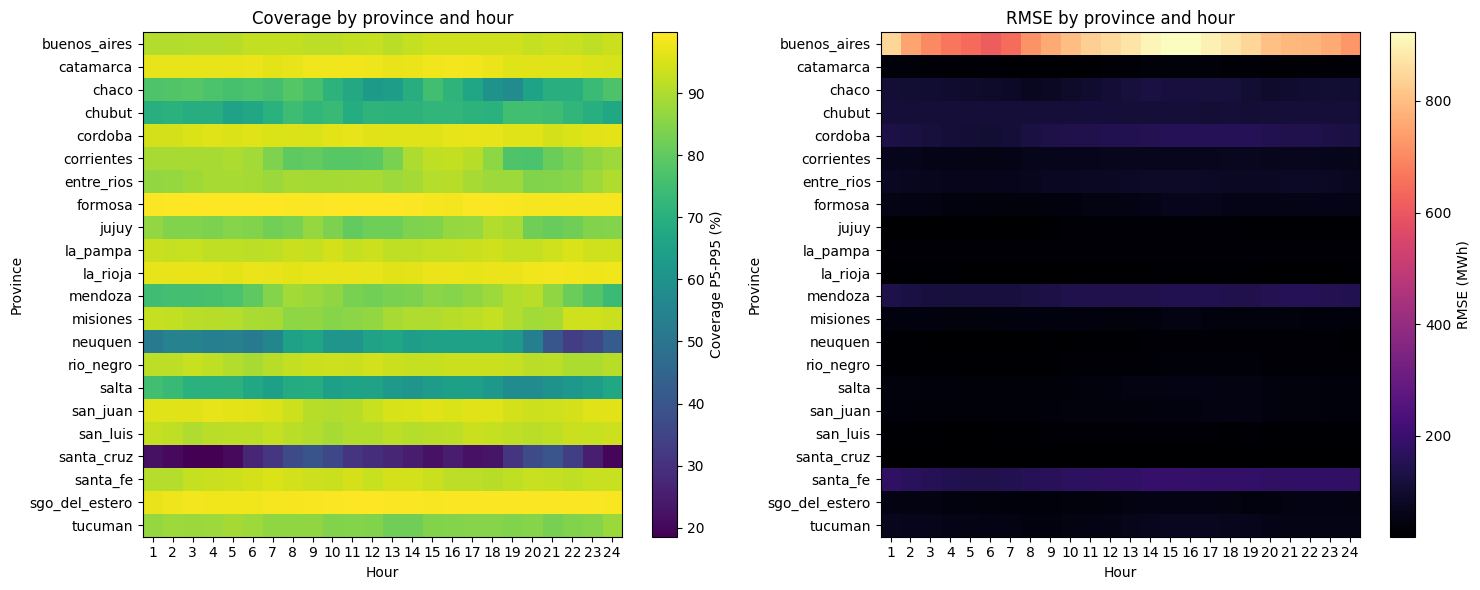

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
image_coverage = axes[0].imshow(coverage_by_hour.to_numpy(), aspect="auto", cmap="viridis")
axes[0].set_title("Coverage by province and hour")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Province")
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(range(1, 25))
axes[0].set_yticks(range(len(coverage_by_hour.index)))
axes[0].set_yticklabels(coverage_by_hour.index)
fig.colorbar(image_coverage, ax=axes[0], label="Coverage P5-P95 (%)")

image_rmse = axes[1].imshow(rmse_by_hour.to_numpy(), aspect="auto", cmap="magma")
axes[1].set_title("RMSE by province and hour")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Province")
axes[1].set_xticks(range(24))
axes[1].set_xticklabels(range(1, 25))
axes[1].set_yticks(range(len(rmse_by_hour.index)))
axes[1].set_yticklabels(rmse_by_hour.index)
fig.colorbar(image_rmse, ax=axes[1], label="RMSE (MWh)")
fig.tight_layout()
plt.show()

## Perfiles reales vs generados

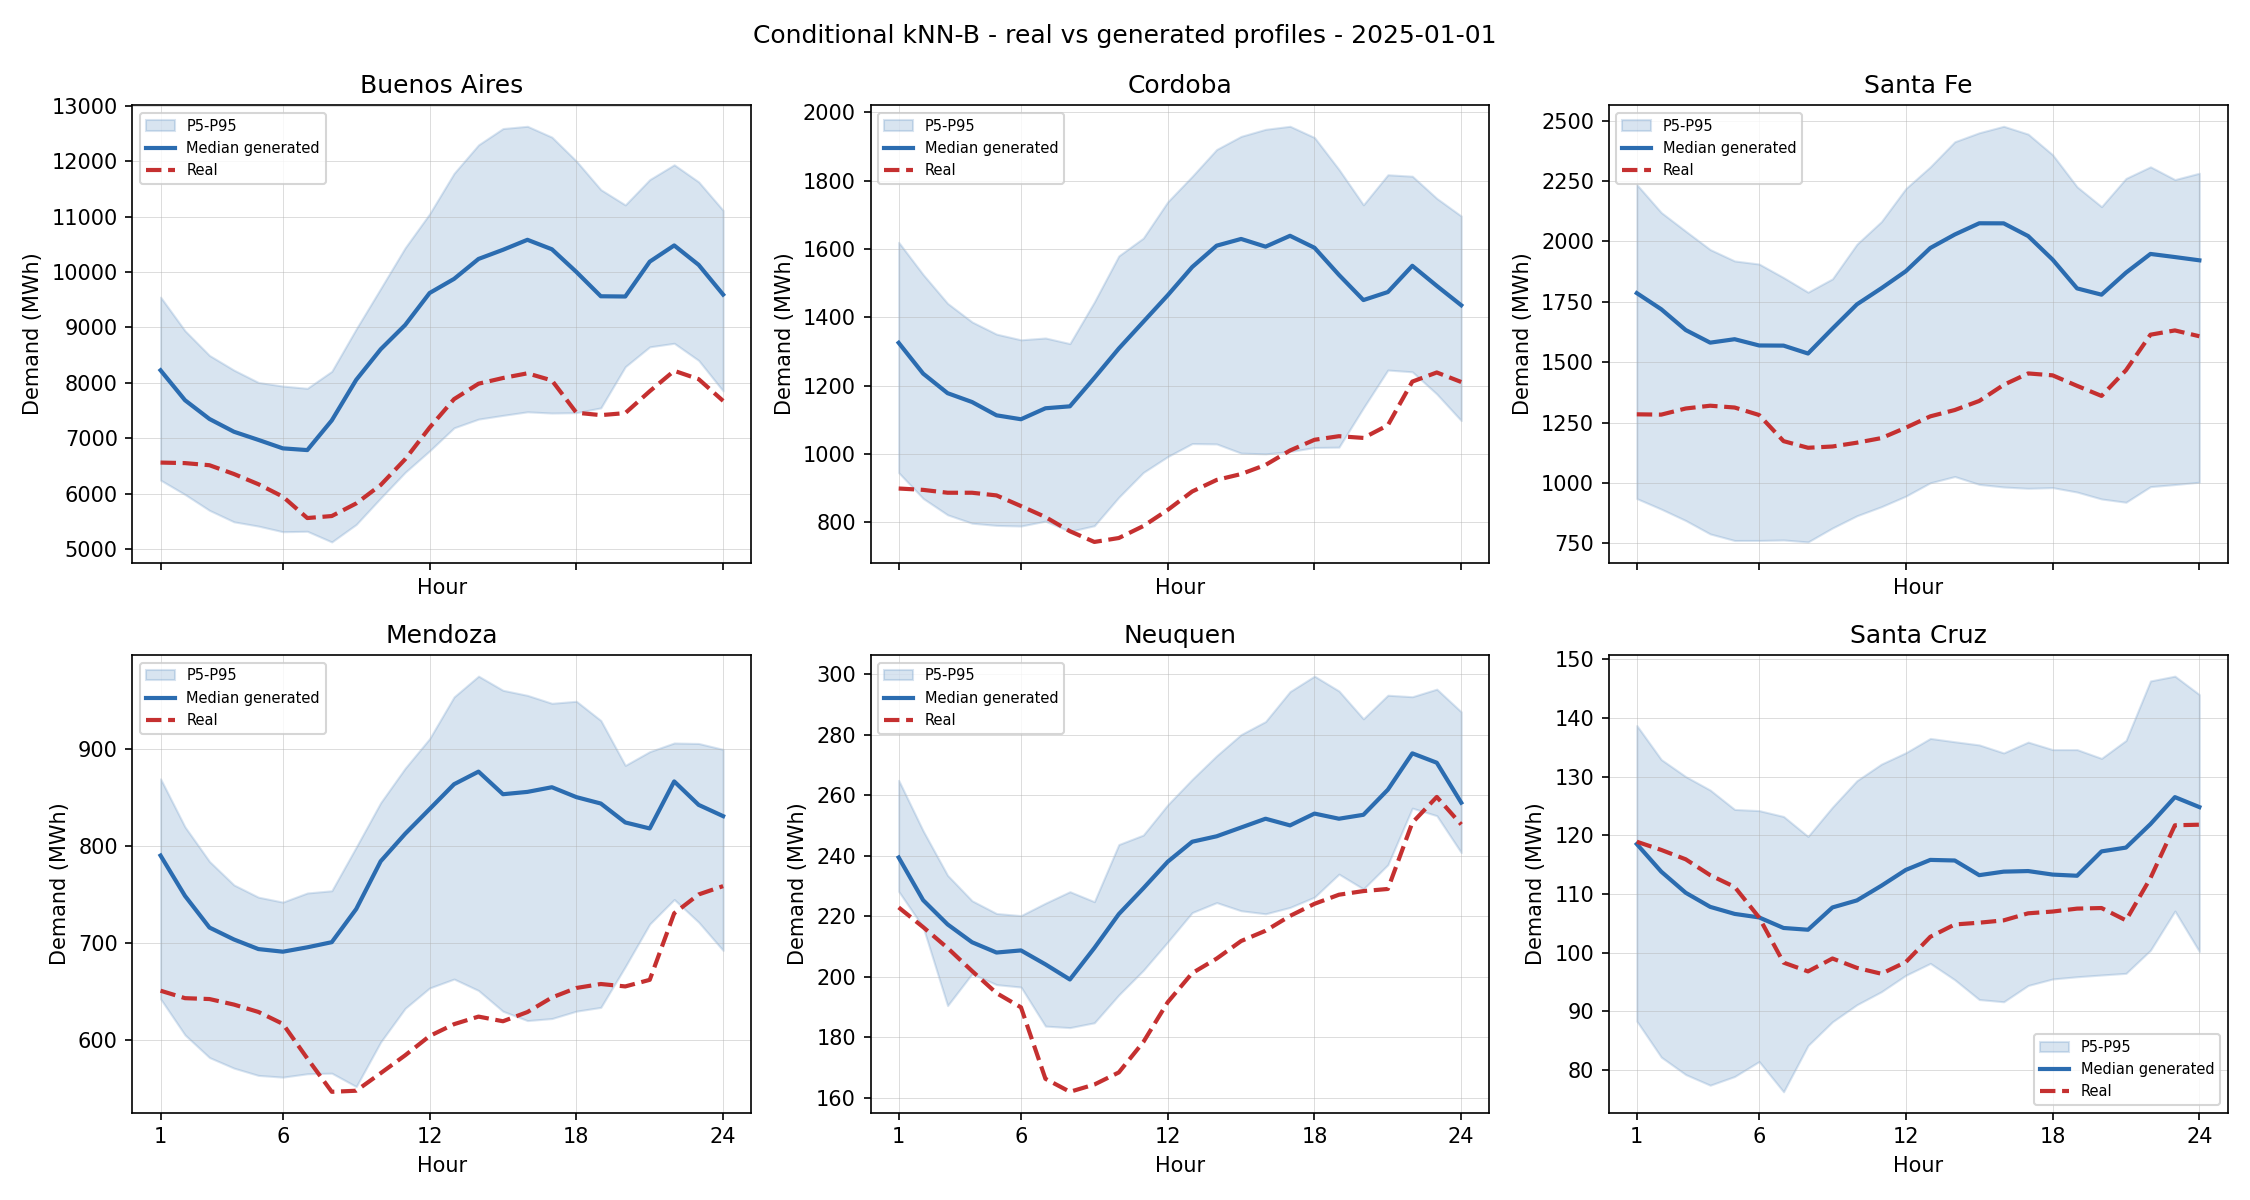

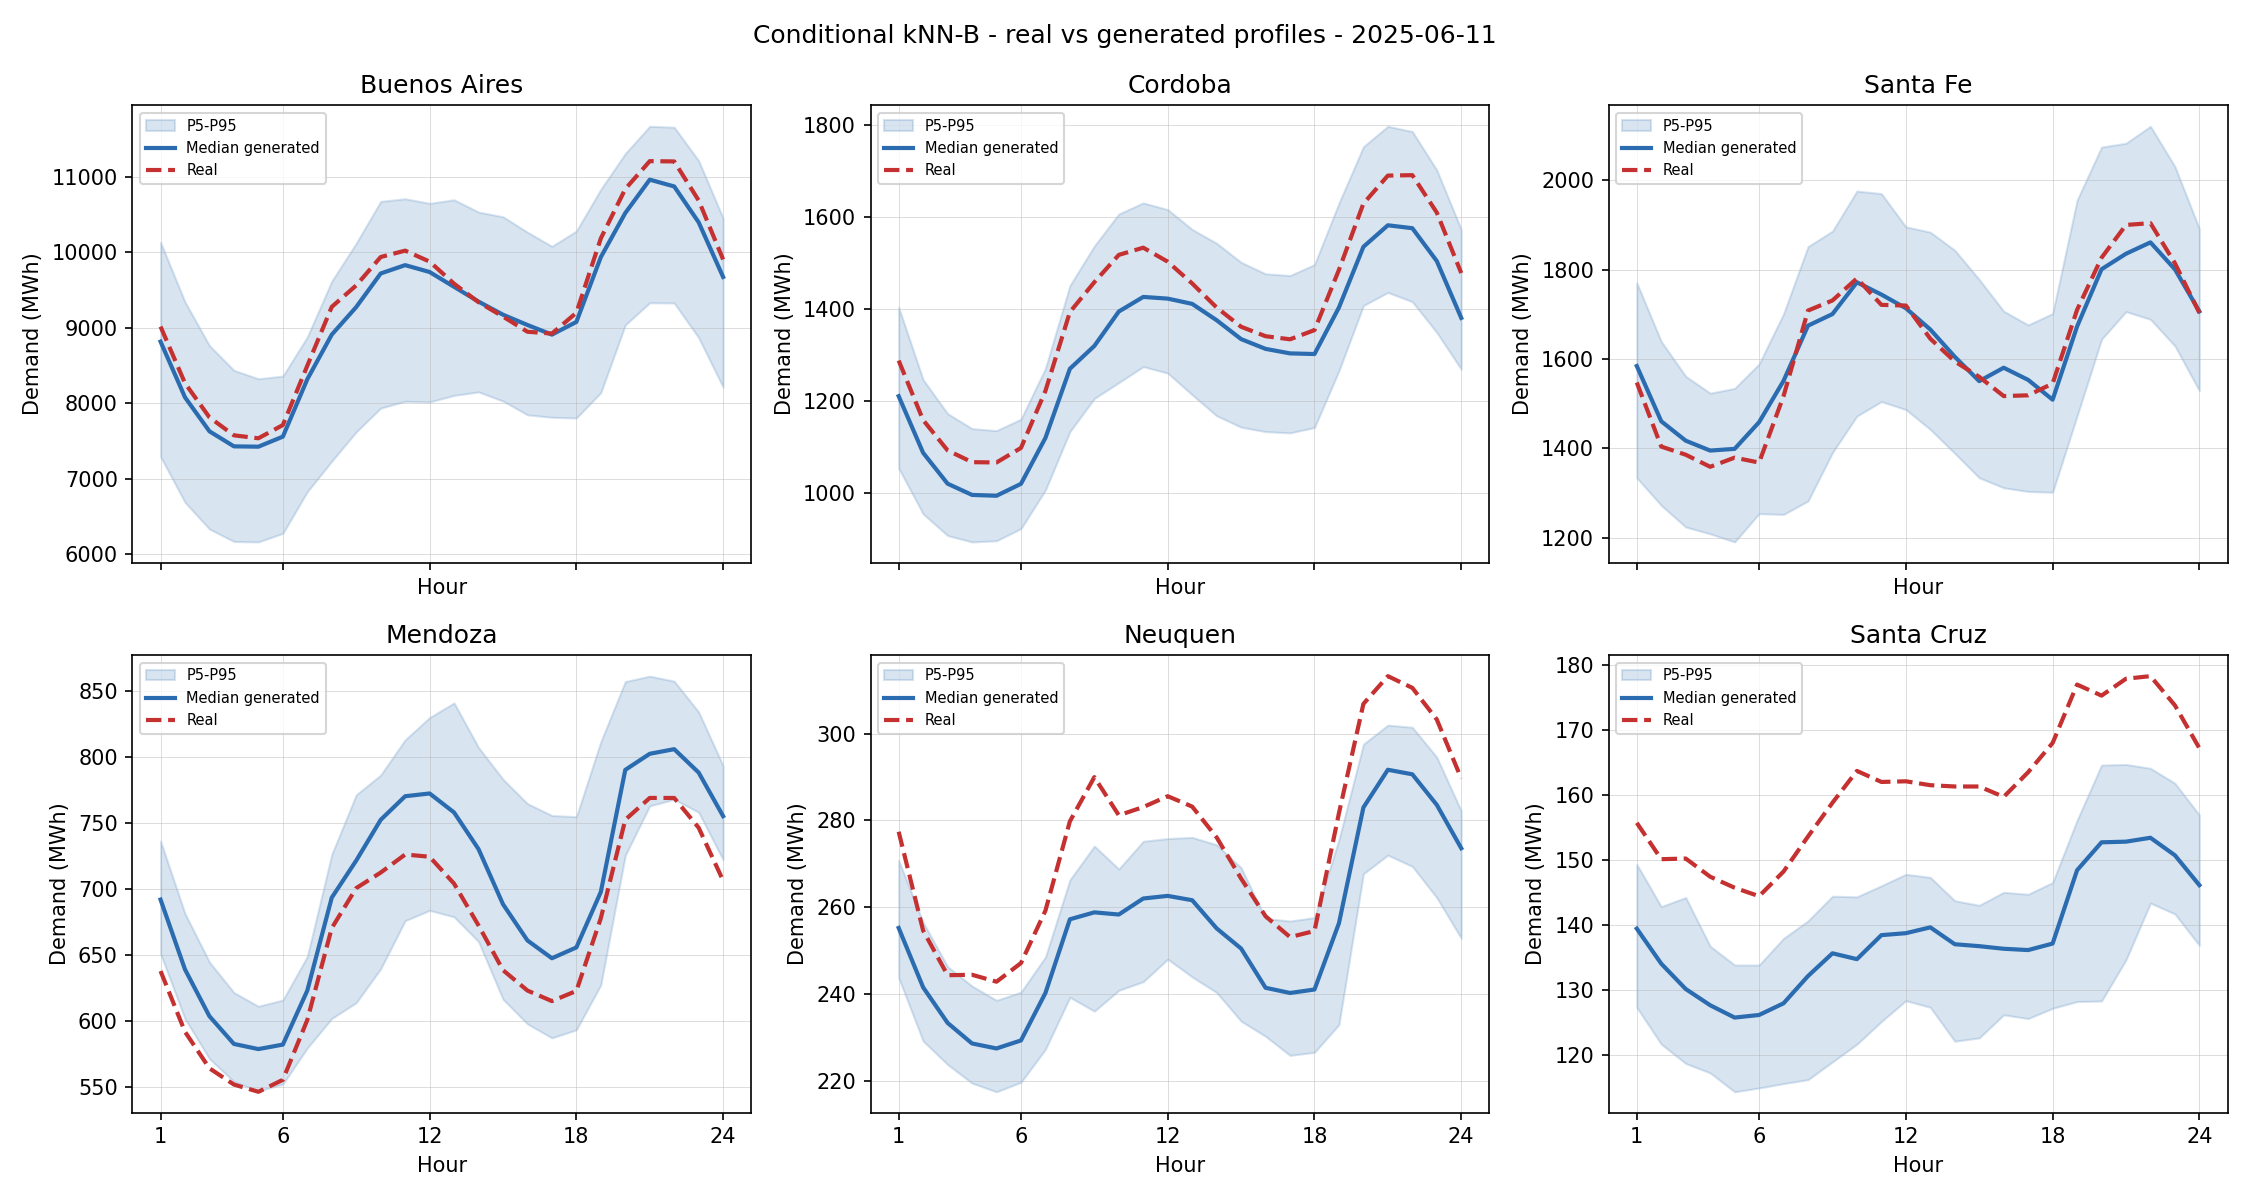

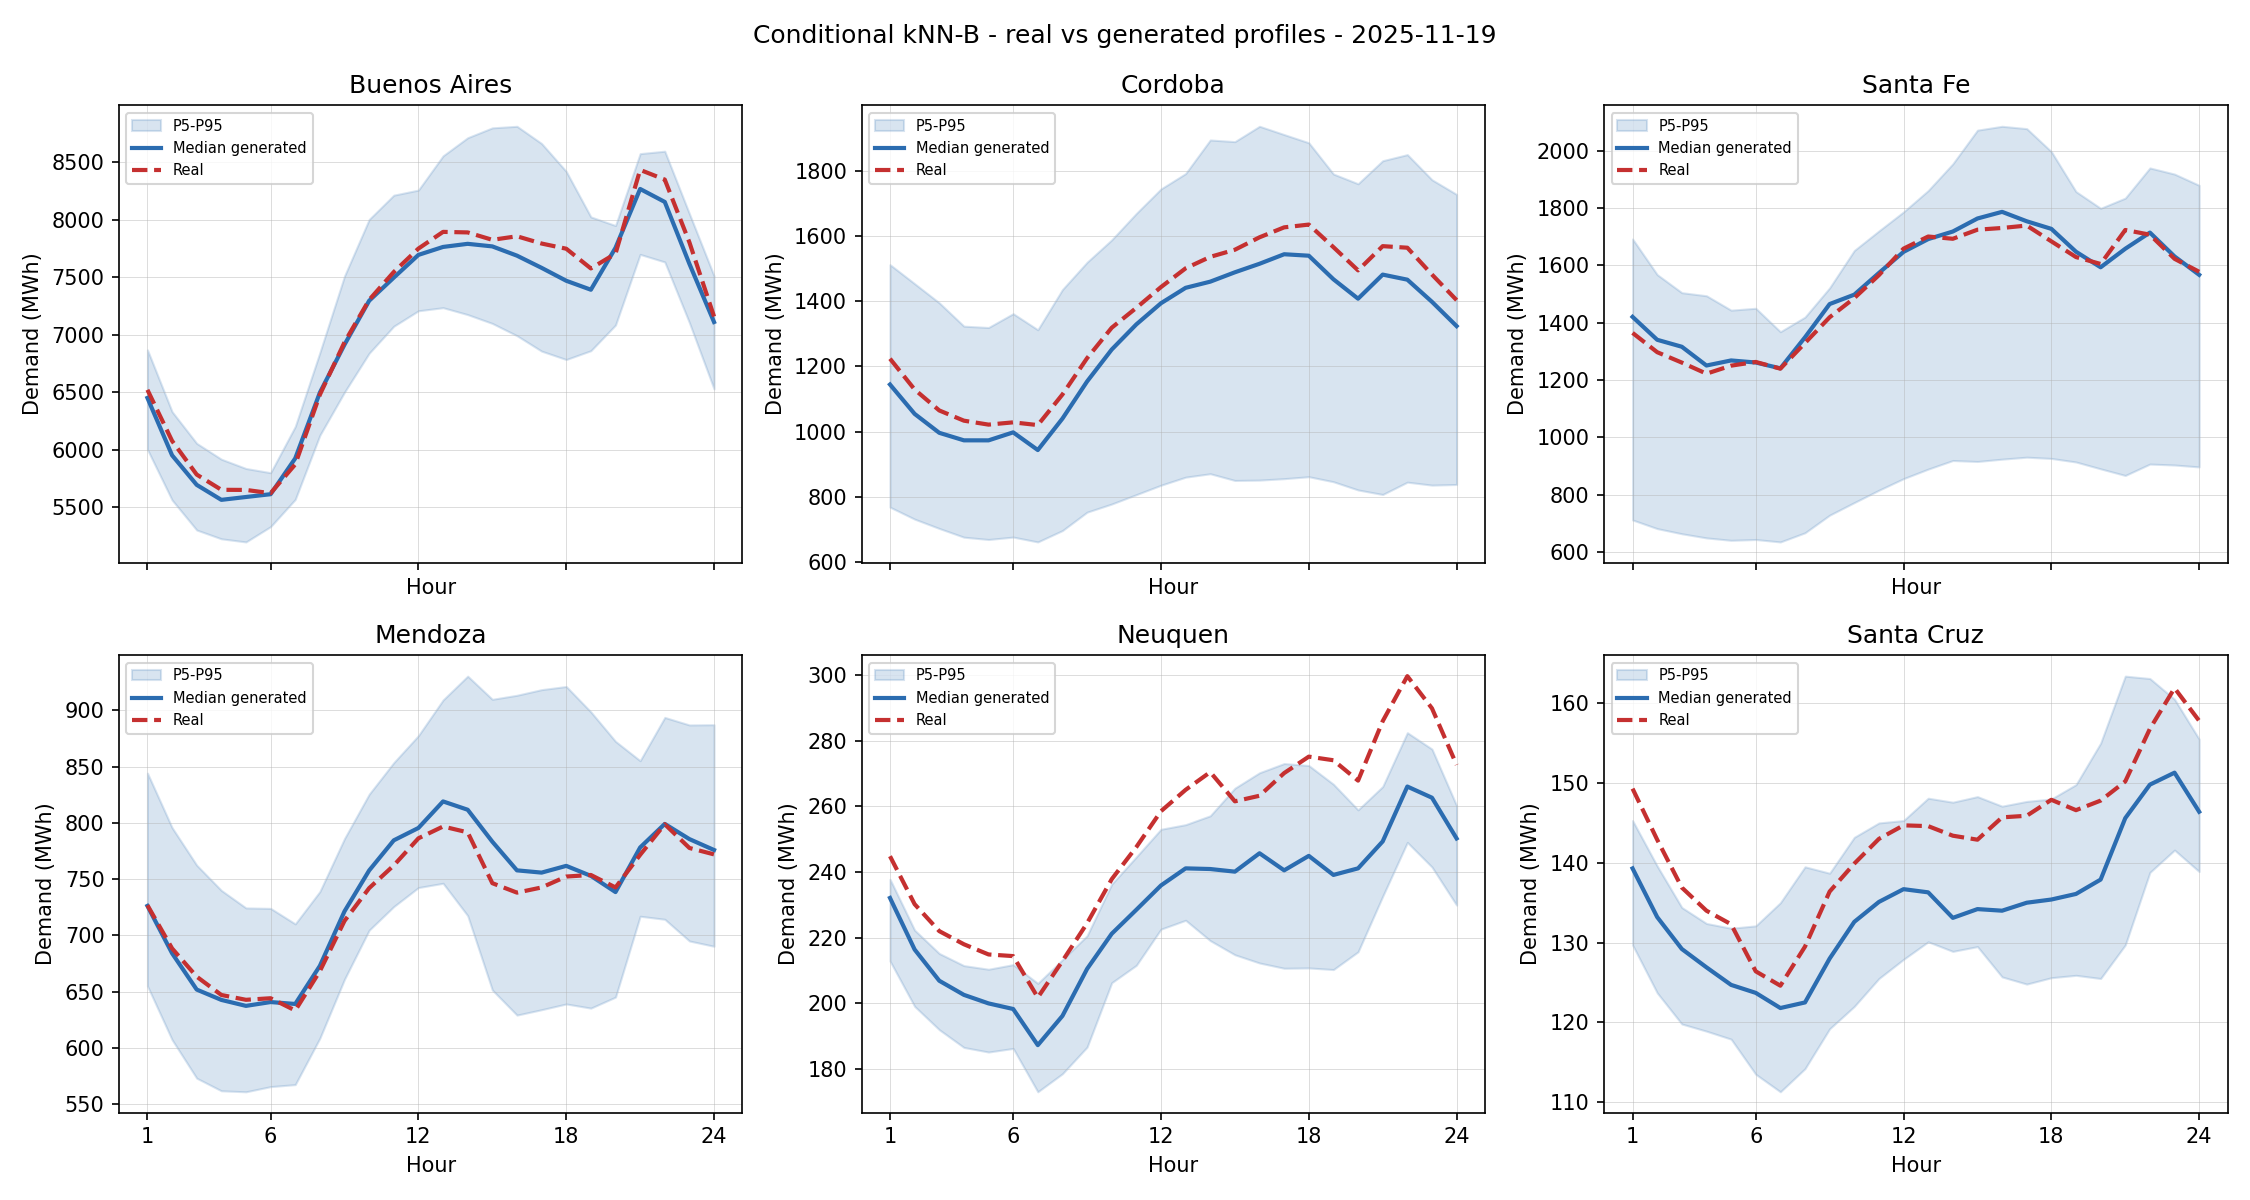

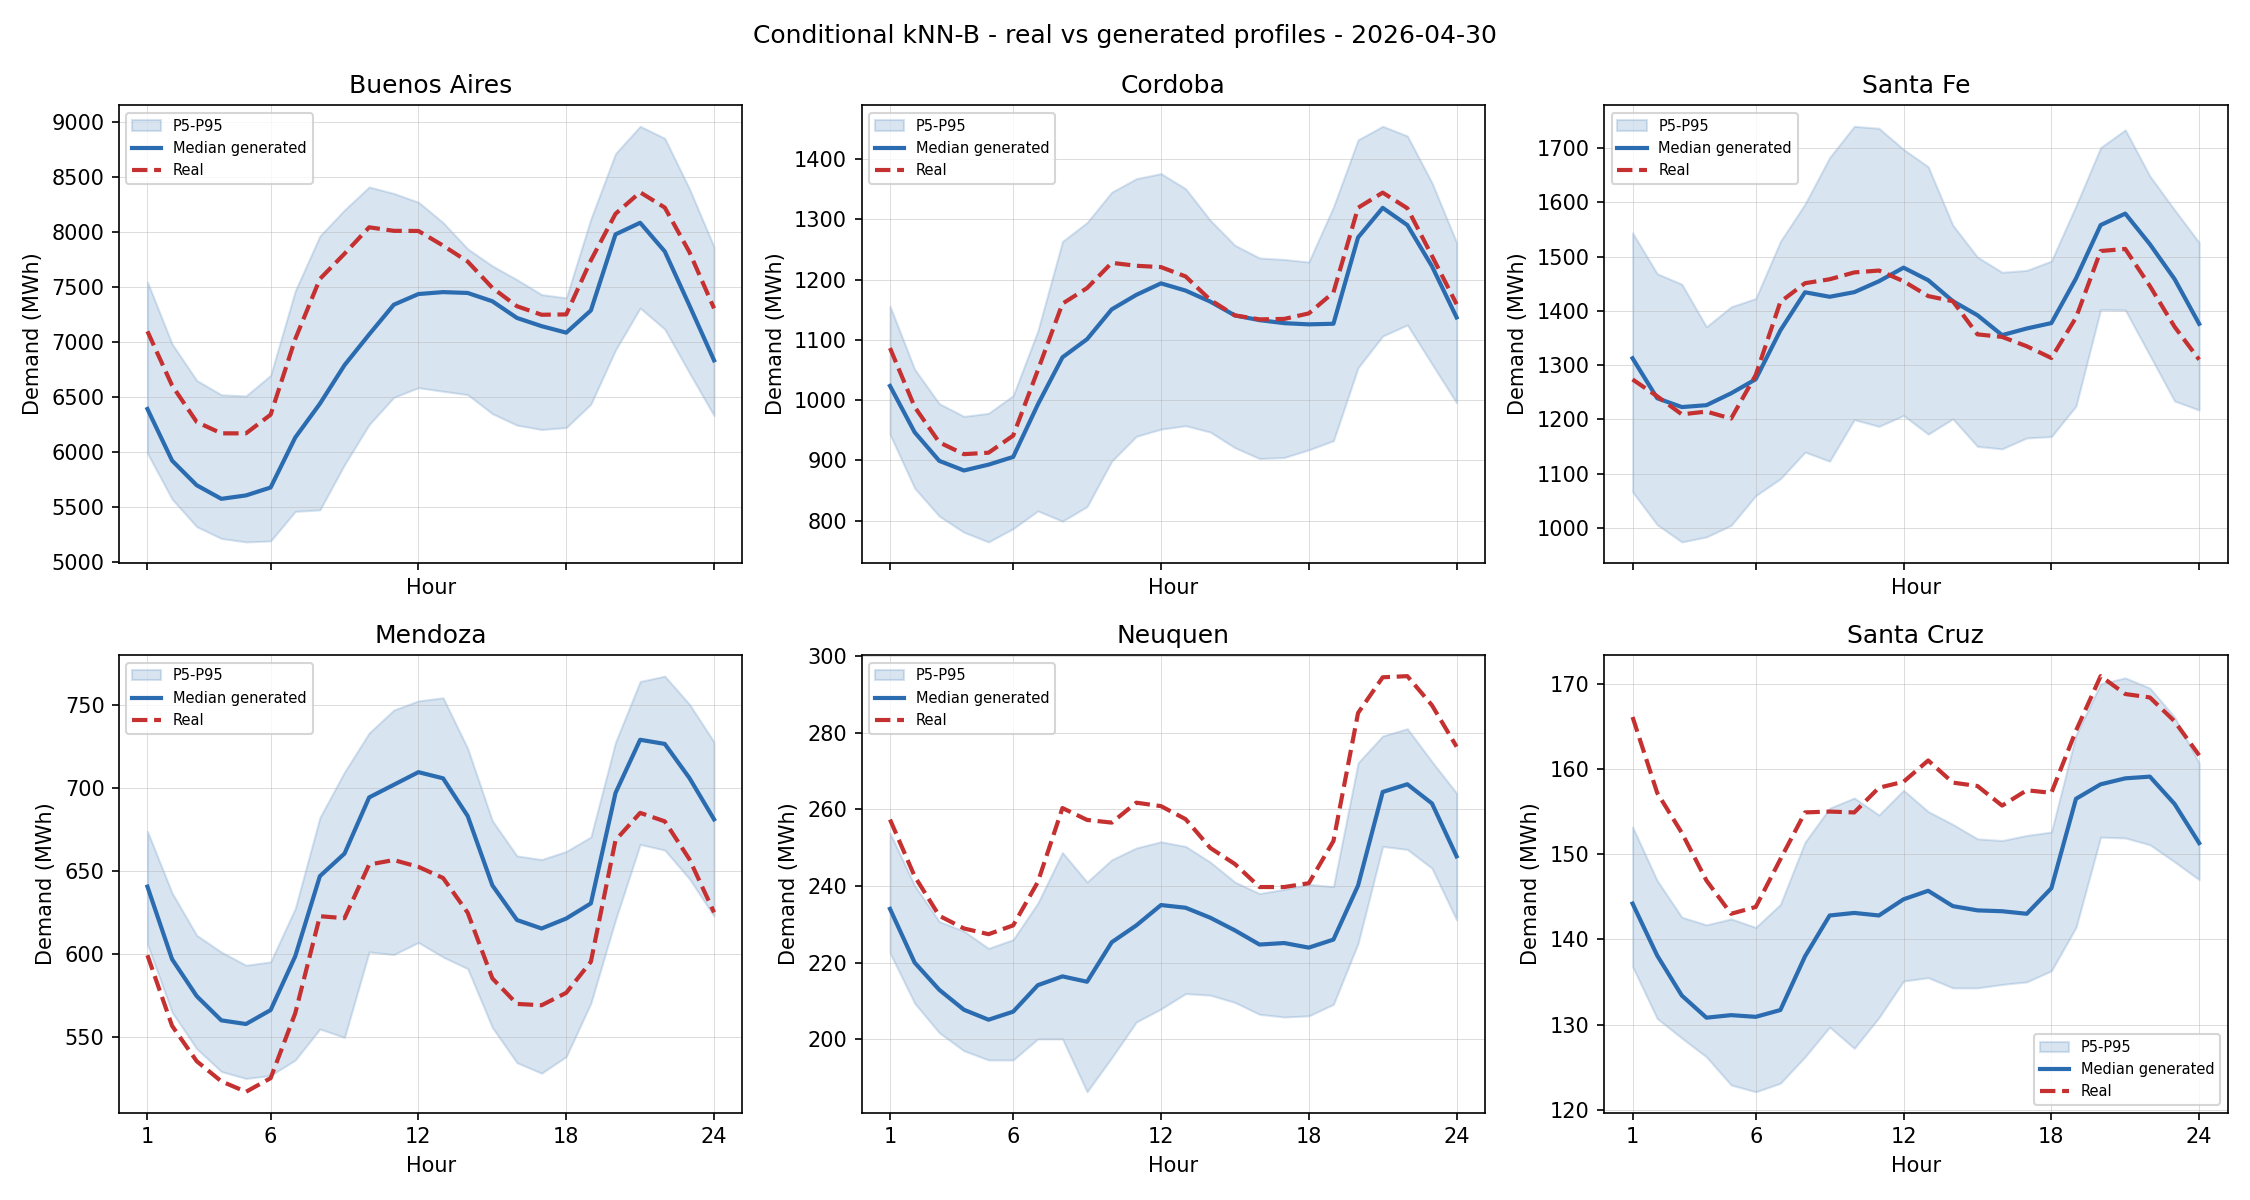

In [10]:
plot_paths = sorted((output_dir / "plots").glob("real_vs_generated_*.png"))
for plot_path in plot_paths:
    display(Image(filename=str(plot_path)))

## Comparacion con CVAE-B

La tabla compara ambos modelos en el mismo espacio provincia-dia de 24 dimensiones. Esto si es comparable con CVAE-B porque ambos reciben el mismo `C` y generan perfiles provinciales de 24 horas. La diferencia conceptual es que CVAE-B aprende una distribucion latente, mientras que kNN-B reutiliza perfiles historicos de contextos similares.

,model,mae_global,rmse_global,mape_energy,coverage,sharpness,diversity_ratio,mmd
0,CVAE-B,108.050000,318.550000,14.375200,81.640000,309.190002,0.058600,0.004000
1,Conditional kNN-B,59.812572,173.856903,8.967692,84.232662,319.617490,0.063435,0.004024


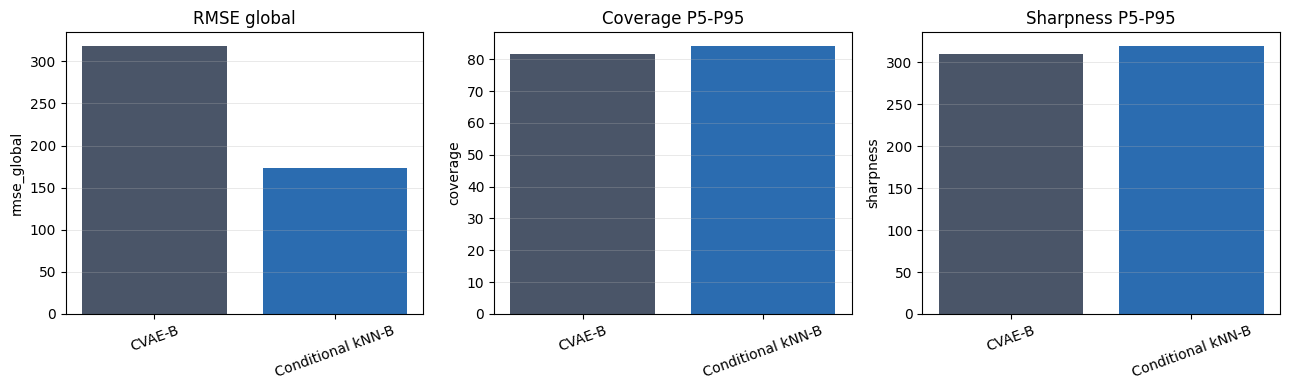

In [11]:
comparison = pd.read_csv(output_dir / "cvae_b_comparison.csv")
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, metric, title in zip(
    axes,
    ["rmse_global", "coverage", "sharpness"],
    ["RMSE global", "Coverage P5-P95", "Sharpness P5-P95"],
):
    axis.bar(comparison["model"], comparison[metric], color=["#4A5568", "#2B6CB0"])
    axis.set_title(title)
    axis.set_ylabel(metric)
    axis.grid(axis="y", linewidth=0.4, alpha=0.5)
    axis.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

## Interpretacion

Este baseline permite evaluar cuanto de la distribucion condicional puede explicarse unicamente con `C`. Si el CVAE-B mejora frente a este baseline, entonces la complejidad adicional del espacio latente se justifica porque captura variabilidad residual no explicada por el contexto. Si el kNN condicional obtiene metricas iguales o mejores, eso indicaria que el contexto disponible ya contiene gran parte de la informacion necesaria y que el CVAE-B no aporta una mejora generativa clara.

En esta corrida, kNN-B queda por encima de CVAE-B en MAE, RMSE y MAPE de energia. Tambien tiene coverage algo mayor, aunque con sharpness levemente mas ancho. La lectura preliminar es que el contexto de CVAE-B contiene mucha informacion predictiva por si solo: un baseline local y no parametico ya recupera perfiles provinciales razonables. Para justificar CVAE-B, habria que mostrar una mejora mas clara en calibracion, diversidad residual o algun analisis donde el espacio latente capture variabilidad que no aparece al samplear vecinos historicos.

La limitacion del kNN-B es importante: al samplear perfiles de train, no extrapola formas nuevas y puede copiar sesgos historicos. Por eso no reemplaza al modelo generativo aprendido; funciona como control fuerte para decidir si la complejidad del CVAE-B esta aportando algo medible.